# Aulas IA Preditiva Modulo1 Semana 11 Aula1 e Aula2

### Pipeline 1

In [1]:
from pathlib import Path

for caminho in ['dados/brutos/airbnb_rio_bruto.csv', 'pipeline_limpeza/__init__.py', 'casos/airbnb/__init__.py']:
    if not Path(caminho).exists():
        raise FileNotFoundError(f'Não encontrei {caminho}. Envie a pasta do projeto antes de continuar.')
print('Projeto encontrado em:', Path.cwd())
# Saída:
# Projeto encontrado em: c:/Users/darwin/aula_pipeline_limpeza


Projeto encontrado em: /home/darwin/IAPreditiva/IA_Analise_preditiva_Aulas_Tecnicas/Modulo1/Semana-11


In [2]:
import pandas as pd

pd.set_option('display.width', 110)
pd.set_option('display.max_columns', 10)

bruto = pd.read_csv('dados/brutos/airbnb_rio_bruto.csv')
print(bruto.shape)
bruto[['name', 'host_name', 'neighbourhood_cleansed', 'price', 'minimum_nights', 'last_review']].head(3)



(3060, 25)


,name,host_name,neighbourhood_cleansed,price,minimum_nights,last_review
0,Vaga para mulheres,Anfitrião 1430,Barra da Tijuca,$68.00,1.0,NaN
1,Beautiful apartment on Ipanema beach,Anfitrião 984,Ipanema,"$1,527.50",1.0,2026-09-10
2,Loft em localização na cidade maravilhosa !,Anfitrião 586,Flamengo,$224.00,5.0,2026-05-05


In [3]:
print(bruto.isna().sum()[lambda s: s > 0])

name                              61
host_name                        124
neighbourhood_group_cleansed    3060
bedrooms                           2
beds                              18
bathrooms_text                     2
price                            271
minimum_nights                    23
maximum_nights                    23
last_review                      569
reviews_per_month                569
review_scores_rating             569
host_response_rate              3060
instant_bookable                3060
dtype: int64


In [4]:
import pandas as pd

class LimpezaSimples:
    """Cada método faz uma operação e devolve um DataFrame."""

    def ler(self, caminho):
        return pd.read_csv(caminho)

    def remover_vazias(self, dados):
        return dados.dropna(axis=1, how='all')

    def converter_preco(self, dados):
        dados = dados.copy()
        texto = dados['price'].str.replace(r'[$,]', '', regex=True)
        dados['price'] = pd.to_numeric(texto, errors='coerce')
        return dados

    def executar(self, caminho):
        return self.converter_preco(self.remover_vazias(self.ler(caminho)))

limpeza = LimpezaSimples()
precos = limpeza.executar('dados/brutos/airbnb_rio_bruto.csv')
precos[['price']].describe().round(1)


,price
count,2789.0
mean,803.3
std,1855.9
min,0.0
25%,291.2
50%,446.7
75%,738.0
max,41556.6


In [5]:
etapas = [limpeza.remover_vazias, limpeza.converter_preco]

dados_pipeline = limpeza.ler('dados/brutos/airbnb_rio_bruto.csv')
for etapa in etapas:
    dados_pipeline = etapa(dados_pipeline)

print('Linhas:', len(dados_pipeline), '| colunas:', dados_pipeline.shape[1])


Linhas: 3060 | colunas: 22


In [6]:
import logging

logging.basicConfig(level=logging.INFO, format='%(levelname)s |   %(message)s', force=True)
log = logging.getLogger('aula')
log.info('Pipeline iniciado')


INFO |   Pipeline iniciado


In [7]:
import pandas as pd

class PipelineSimples:
    COLUNAS_OBRIGATORIAS = ['id', 'price', 'minimum_nights', 'neighbourhood_cleansed', 'room_type']

    def validar(self, dados):
        faltam = []
        for nome_coluna in self.COLUNAS_OBRIGATORIAS:
            if nome_coluna not in dados.columns:
                faltam.append(nome_coluna)
        #faltam = [c for c in self.COLUNAS_OBRIGATORIAS if c not in dados.columns]
        
        if len(faltam) > 0:
            raise ValueError(f'Esquema inválido, faltam as colunas: {faltam}')
        return dados



pipeline = PipelineSimples()
try:
    pipeline.validar(pd.DataFrame({'id': [1], 'preco': [10]}))
except ValueError as erro:
    print('ERRO:', erro)

pipeline.validar(bruto)
print('Esquema OK:', bruto.shape)



ERRO: Esquema inválido, faltam as colunas: ['price', 'minimum_nights', 'neighbourhood_cleansed', 'room_type']
Esquema OK: (3060, 25)


In [8]:
class PipelineSimplesCompleto(PipelineSimples):
    """Herda validar() e acrescenta as etapas de leitura, limpeza e saída."""

    def __init__(self, entrada, saida):
        self.entrada = entrada
        self.saida = saida

    def ler(self):
        return pd.read_csv(self.entrada)

    def limpar(self, dados):
        linhas_antes = len(dados)
        dados = dados.dropna(axis=1, how='all').drop_duplicates()
        dados['price'] = pd.to_numeric(dados['price'].str.replace(r'[$,]', '', regex=True), errors='coerce')
        log.info('linhas removidas (duplicadas): %d', linhas_antes - len(dados))
        return dados

    def salvar(self, dados):
        dados.to_csv(self.saida, index=False)
        return dados

    def executar(self):
        return self.salvar(self.limpar(self.validar(self.ler())))

simples = PipelineSimplesCompleto('dados/brutos/airbnb_rio_bruto.csv',
                                  'dados/processados/listings_simples.csv').executar()
simples.shape


INFO |   linhas removidas (duplicadas): 60


(3000, 22)

### Limpeza de dados

Linhas e colunas: (3060, 25)


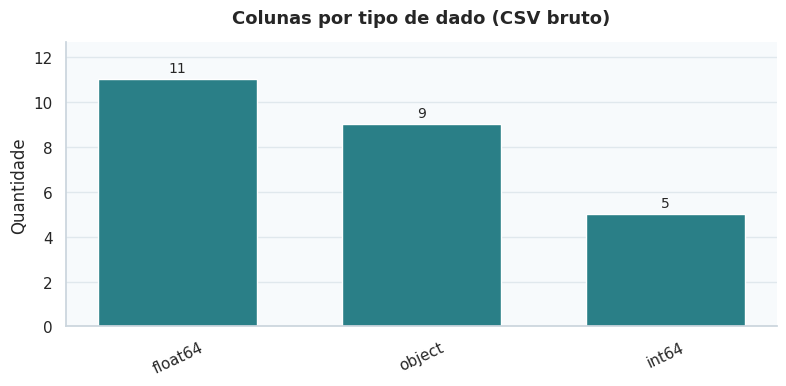

In [9]:
from pipeline_limpeza import Graficos

tipos_bruto = bruto.dtypes.astype(str).value_counts()
print('Linhas e colunas:', bruto.shape)

Graficos(bruto).barras_serie(tipos_bruto, 'Colunas por tipo de dado (CSV bruto)')


In [10]:
print(bruto.columns)

bruto['neighbourhood_cleansed'].value_counts().head(6)



Index(['id', 'name', 'host_name', 'neighbourhood_cleansed', 'neighbourhood_group_cleansed', 'room_type',
       'property_type', 'latitude', 'longitude', 'accommodates', 'bedrooms', 'beds', 'bathrooms_text',
       'price', 'minimum_nights', 'maximum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month',
       'review_scores_rating', 'availability_365', 'host_is_superhost', 'host_response_rate',
       'host_listings_count', 'instant_bookable'],
      dtype='object')


neighbourhood_cleansed
Copacabana                  969
Ipanema                     245
Barra da Tijuca             228
Centro                      199
Botafogo                    155
Recreio dos Bandeirantes    149
Name: count, dtype: int64

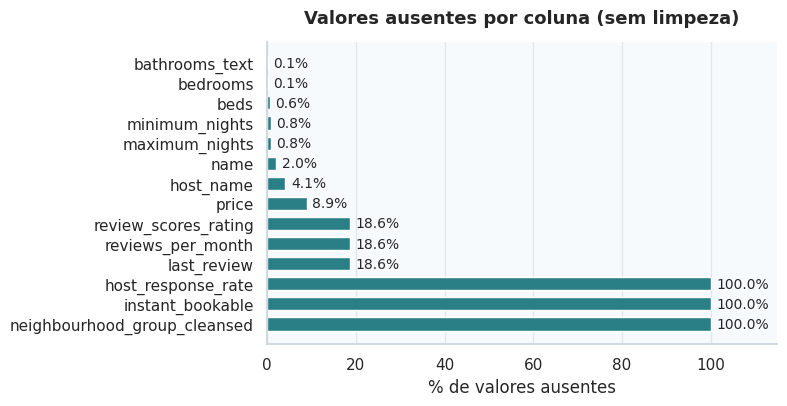

In [11]:
from pipeline_limpeza import Graficos

Graficos(bruto).percentual_ausentes('Valores ausentes por coluna (sem limpeza)')


Colunas 100% vazias: ['neighbourhood_group_cleansed', 'instant_bookable', 'host_response_rate']


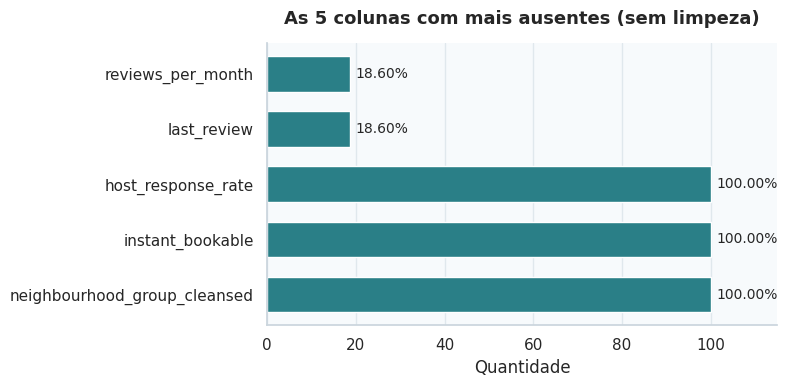

In [12]:
from pipeline_limpeza import Graficos

pct = bruto.isna().mean().mul(100).sort_values(ascending=False).head(5)
print('Colunas 100% vazias:', list(pct[pct == 100].index))
Graficos(bruto).barras_serie(pct.round(1), 'As 5 colunas com mais ausentes (sem limpeza)', fmt='%.2f%%', horizontal=True)
# Saída:
# Colunas 100% vazias: ['neighbourhood_group_cleansed', 'instant_bookable', 'host_response_rate']


In [13]:
from pipeline_limpeza import TratadorAusentes, RegistroDecisoes

registro = RegistroDecisoes()
tratador = TratadorAusentes(bruto, registro)
tratador.remover_colunas_vazias()
print('Colunas antes:', bruto.shape[1], '| depois:', tratador.dados.shape[1])
registro.tabela()[['coluna', 'problema', 'acao']]


INFO |   TratadorAusentes | neighbourhood_group_cleansed: removi a coluna (linhas removidas: 0)
INFO |   TratadorAusentes | host_response_rate: removi a coluna (linhas removidas: 0)
INFO |   TratadorAusentes | instant_bookable: removi a coluna (linhas removidas: 0)


Colunas antes: 25 | depois: 22


,coluna,problema,acao
0,neighbourhood_group_cleansed,100% vazia,removi a coluna
1,host_response_rate,100% vazia,removi a coluna
2,instant_bookable,100% vazia,removi a coluna


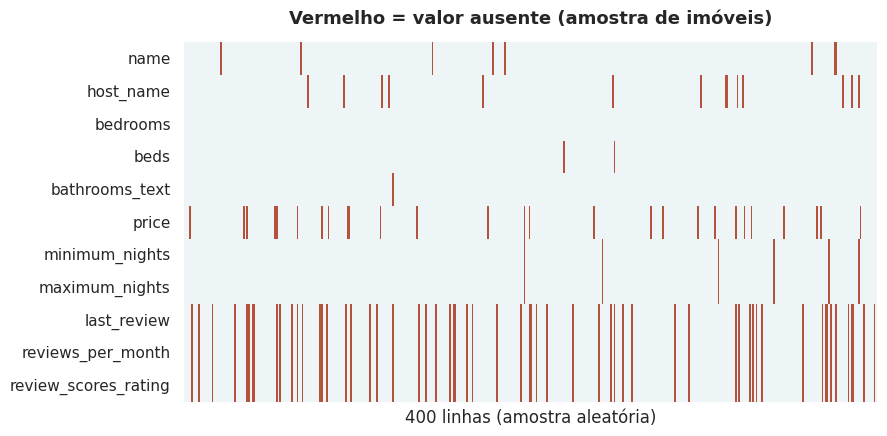

In [14]:
from script_functions import Visualizacao

Visualizacao.mapa_ausentes(tratador.dados, 'Vermelho = valor ausente (amostra de imóveis)')


In [15]:
tratador.preencher('name', 'sem nome', 'o nome não entra no modelo; o imóvel continua válido')
tratador.preencher('host_name', 'não informado', 'identificação do anfitrião; não afeta o preço')
tratador.dados[['name', 'host_name']].isna().sum()


INFO |   TratadorAusentes | name: preenchi com 'sem nome' (linhas removidas: 0)
INFO |   TratadorAusentes | host_name: preenchi com 'não informado' (linhas removidas: 0)


name         0
host_name    0
dtype: int64

In [16]:
tratador.preencher('reviews_per_month', 0, 'sem avaliação, a taxa mensal é zero')
print('Taxa ausente restante:', tratador.dados['reviews_per_month'].isna().sum())
print(tratador.dados[['number_of_reviews', 'reviews_per_month']].head(4))
print('Datas ausentes:', tratador.dados['last_review'].isna().sum())
tratador.dados[['last_review']].head(3)



INFO |   TratadorAusentes | reviews_per_month: preenchi com 0 (linhas removidas: 0)


Taxa ausente restante: 0
   number_of_reviews  reviews_per_month
0                  0               0.00
1                 63               3.05
2                  3               0.20
3                 13               0.63
Datas ausentes: 569


,last_review
0,NaN
1,2026-09-10
2,2026-05-05


Exemplo: $829.00 -> 829.0


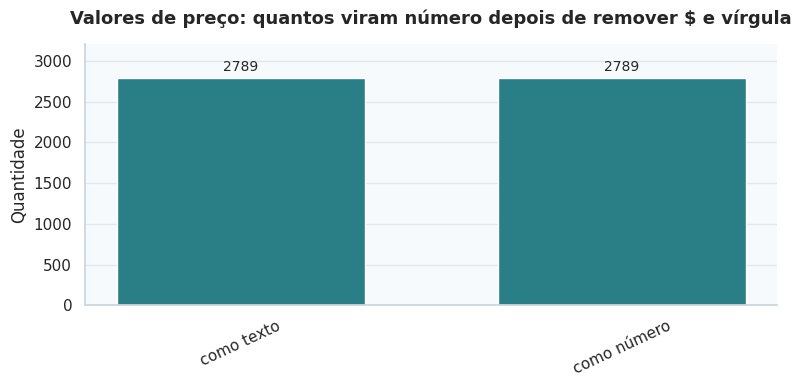

In [17]:
from pipeline_limpeza import Graficos

texto = bruto['price'].dropna().astype(str)
numeros = pd.to_numeric(texto.str.replace(r'[$,]', '', regex=True), errors='coerce')
print('Exemplo:', texto.iloc[10], '->', numeros.iloc[10])
resumo = pd.Series({'como texto': len(texto), 'como número': int(numeros.notna().sum())})
Graficos(bruto).barras_serie(resumo, 'Valores de preço: quantos viram número depois de remover $ e vírgula')


In [18]:
from pipeline_limpeza import TratadorTipos

tipos = TratadorTipos(tratador.dados, registro)
tipos.converter_numerico('price')
tipos.converter_data('last_review')
print(tipos.dados['price'].dtype, '|', tipos.dados['last_review'].dtype)


INFO |   TratadorTipos | price: converti para número (0 valores não convertidos viraram NaN) (linhas removidas: 0)
INFO |   TratadorTipos | last_review: converti para datetime (errors='coerce') (linhas removidas: 0)


Float64 | datetime64[ns]


In [19]:
tipos.dados.groupby('neighbourhood_cleansed')['price'].agg('median')\
    .reset_index().sort_values(by='price', ascending=False).round(2).head(5)

,neighbourhood_cleansed,price
48,Joá,6919.5
102,Vila Valqueire,1242.2
59,Osvaldo Cruz,900.0
41,Ipanema,889.0
77,Sampaio,884.0


In [20]:
from pipeline_limpeza import TratadorUnidades

unidades = TratadorUnidades(tipos.dados, registro).extrair_banheiros()
unidades.dados[['bathrooms_text', 'banheiros', 'banheiro_compartilhado']].head(4)


INFO |   TratadorUnidades | bathrooms_text: criei 'banheiros' e 'banheiro_compartilhado' (linhas removidas: 0)


,bathrooms_text,banheiros,banheiro_compartilhado
0,1 shared bath,1.0,True
1,2.5 baths,2.5,False
2,1 bath,1.0,False
3,1 bath,1.0,False


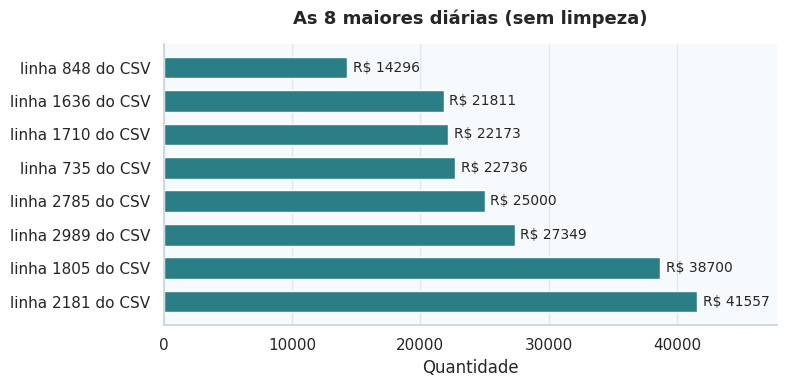

In [21]:
from pipeline_limpeza import Graficos

precos = pd.to_numeric(bruto['price'].astype('string').str.replace(r'[$,]', '', regex=True), errors='coerce')
maiores = precos.nlargest(8)
rotulos = [f'linha {i + 2} do CSV' for i in maiores.index]
Graficos(bruto).barras_serie(pd.Series(maiores.values, index=rotulos), 'As 8 maiores diárias (sem limpeza)', fmt='R$ %.0f', horizontal=True)


imóveis acima de R$ 3.000: 85 de 2789


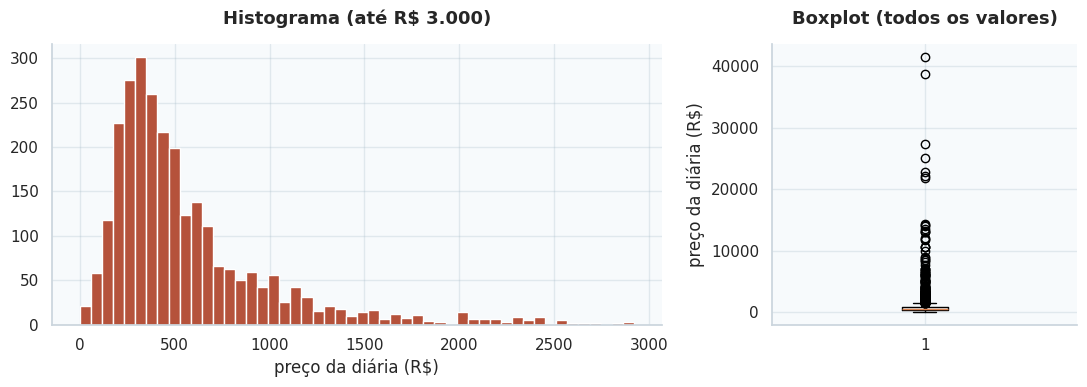

In [22]:
import matplotlib.pyplot as plt

precos = pd.to_numeric(bruto['price'].astype('string').str.replace(r'[$,]', '', regex=True), errors='coerce').dropna()
print('imóveis acima de R$ 3.000:', int((precos >= 3000).sum()), 'de', len(precos))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={'width_ratios': [2, 1]})
ax1.hist(precos[precos < 3000], bins=50, color='#B5523B', edgecolor='white')
ax1.set_title('Histograma (até R$ 3.000)')
ax1.set_xlabel('preço da diária (R$)')
ax2.boxplot(precos)
ax2.set_title('Boxplot (todos os valores)')
ax2.set_ylabel('preço da diária (R$)')
plt.tight_layout()
plt.show()


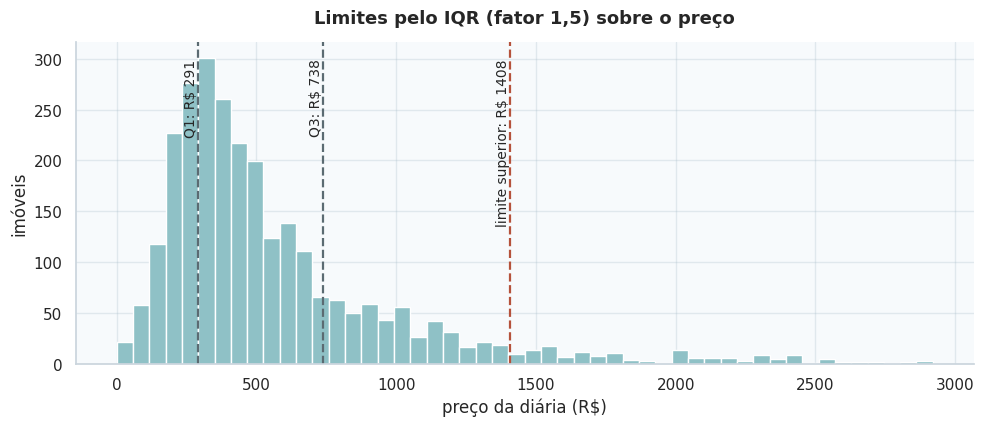

In [23]:
import matplotlib.pyplot as plt
from pipeline_limpeza import TratadorOutliers

limites = TratadorOutliers(unidades.dados, registro).limites('price')
preco = unidades.dados['price'].dropna()
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.hist(preco[preco < 3000], bins=50, color='#8FC1C6', edgecolor='white')
for nome, valor in [('Q1', limites['Q1']), ('Q3', limites['Q3']), ('limite superior', limites['superior'])]:
    ax.axvline(valor, color='#B5523B' if nome.startswith('limite') else '#5B6B72', ls='--', lw=1.6)
    ax.text(valor, ax.get_ylim()[1] * 0.95, f'{nome}: R$ {valor:.0f}', rotation=90, ha='right', va='top', fontsize=10)
ax.set_title('Limites pelo IQR (fator 1,5) sobre o preço')
ax.set_xlabel('preço da diária (R$)')
ax.set_ylabel('imóveis')
plt.tight_layout()
plt.show()


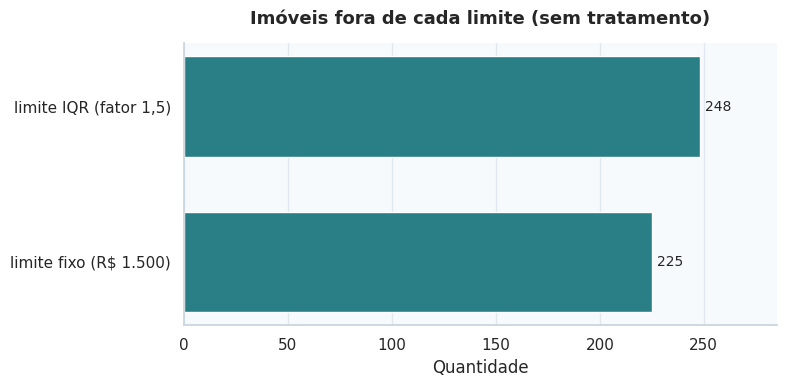

In [24]:
from pipeline_limpeza import Graficos, TratadorOutliers

marcados = TratadorOutliers(unidades.dados, registro).marcar('price')
contagem = pd.Series({
    'limite fixo (R$ 1.500)': int((unidades.dados['price'] > 1500).sum()),
    'limite IQR (fator 1,5)': int(marcados.sum()),
})
Graficos(unidades.dados).barras_serie(contagem, 'Imóveis fora de cada limite (sem tratamento)', horizontal=True)


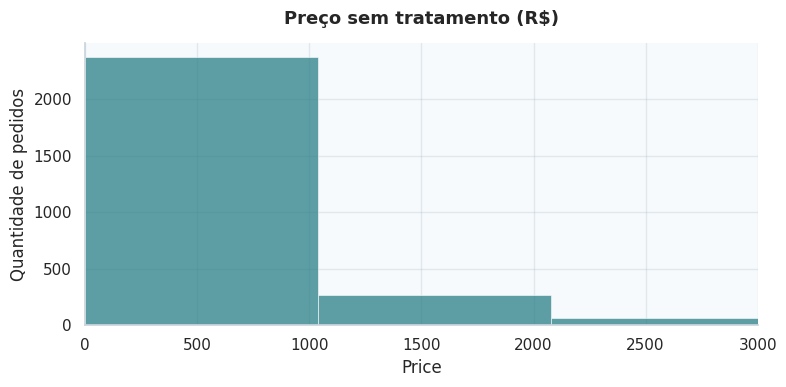

In [25]:
from pipeline_limpeza import Graficos

grafico_sujo = Graficos(unidades.dados)
grafico_sujo.histograma('price', 'Preço sem tratamento (R$)', bins=40, limite=(0, 3000))


In [26]:
from pipeline_limpeza import TratadorOutliers

outliers = TratadorOutliers(unidades.dados, registro)
limites = outliers.limites('price')
{k: round(v, 1) for k, v in limites.items()}


{'Q1': np.float64(291.2),
 'Q3': np.float64(738.0),
 'IQR': np.float64(446.8),
 'inferior': np.float64(-378.9),
 'superior': np.float64(1408.1)}

In [27]:
tratado = TratadorOutliers(unidades.dados, registro)
tratado.limitar('price')

resumo = pd.DataFrame({
    'sem tratamento': [unidades.dados['price'].mean(), unidades.dados['price'].median()],
    'com capping IQR': [tratado.dados['price'].mean(), tratado.dados['price'].median()],
}, index=['média', 'mediana']).round(1)
print(resumo)

INFO |   TratadorOutliers | price: limitei 248 valores aos limites (linhas removidas: 0)


         sem tratamento  com capping IQR
média             803.3            569.1
mediana           446.7            446.7


In [28]:
from pipeline_limpeza import TratadorDuplicados

duplicadas = TratadorDuplicados(unidades.dados, registro)
print('Linhas repetidas:', duplicadas.contar())
unidades.dados[unidades.dados.duplicated(keep=False)].sort_values('id')[['id', 'name', 'price']].head(10)


Linhas repetidas: 60


,id,name,price
804,290513,Charming house in Urca 400 meters from the beach,378.95
1915,290513,Charming house in Urca 400 meters from the beach,378.95
1883,1713671,Studio Loft em ponto nobre de Ipanema,567.67
464,1713671,Studio Loft em ponto nobre de Ipanema,567.67
1478,2775106,3 bedr in front of gate 18 Maracanã,850.0
511,2775106,3 bedr in front of gate 18 Maracanã,850.0
4,11185708,Copa pé na areia c/vista do Pão de Açúcar - 500MB,1522.5
970,11185708,Copa pé na areia c/vista do Pão de Açúcar - 500MB,1522.5
2887,14882341,Amazing apt in the heart of Copacabana!,968.5
374,14882341,Amazing apt in the heart of Copacabana!,968.5


In [29]:
print('ids repetidos:', TratadorDuplicados(unidades.dados, registro).contar(subset=['id']))

ids repetidos: 60


In [30]:
zeros = unidades.dados[unidades.dados['price'] == 0]
print('Imóveis com preço zero:', len(zeros))
zeros[['id', 'neighbourhood_cleansed', 'price']].head(10)


Imóveis com preço zero: 15


,id,neighbourhood_cleansed,price
72,1427752799849615348,Camorim,0.0
280,49318721,Barra da Tijuca,0.0
506,1771826032081000407,Recreio dos Bandeirantes,0.0
554,620353684551426630,Itanhangá,0.0
718,278679,Copacabana,0.0
1132,1726788237767384162,Copacabana,0.0
1268,1561933240308322881,Santa Teresa,0.0
1622,923784,Copacabana,0.0
1697,1449530881143329370,Copacabana,0.0
2116,53940377,Copacabana,0.0


In [31]:
from pipeline_limpeza import TratadorConsistencia
from pipeline_limpeza.config import REGRAS_NEGOCIO

consistencia = TratadorConsistencia(unidades.dados, registro, regras=REGRAS_NEGOCIO)
consistencia.relatorio()


price: preço maior que zero             15
minimum_nights: entre 1 e 365 noites     0
accommodates: entre 1 e 16 hóspedes      0
Name: linhas_invalidas, dtype: int64

In [32]:
registro.tabela()[['coluna', 'problema', 'acao', 'linhas_removidas']]

,coluna,problema,acao,linhas_removidas
0,neighbourhood_group_cleansed,100% vazia,removi a coluna,0
1,host_response_rate,100% vazia,removi a coluna,0
2,instant_bookable,100% vazia,removi a coluna,0
3,name,61 ausentes,preenchi com 'sem nome',0
4,host_name,124 ausentes,preenchi com 'não informado',0
5,reviews_per_month,569 ausentes,preenchi com 0,0
6,price,número guardado como texto,converti para número (0 valores não convertido...,0
7,last_review,data guardada como texto,converti para datetime (errors='coerce'),0
8,bathrooms_text,número e unidade no mesmo texto,criei 'banheiros' e 'banheiro_compartilhado',0
9,price,outliers pelo IQR (fator 1.5),limitei 248 valores aos limites,0


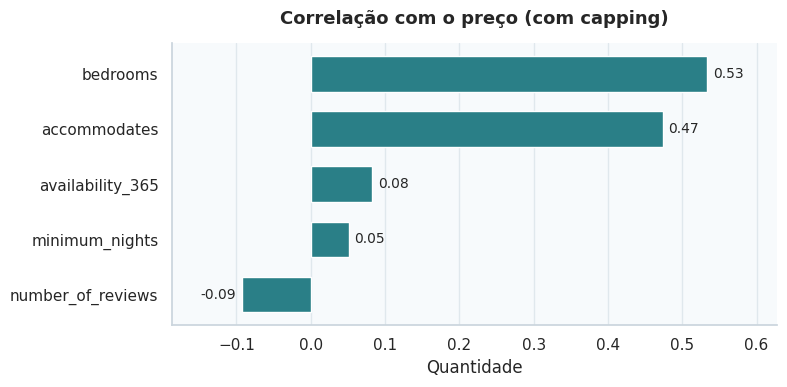

In [33]:
from pipeline_limpeza import Graficos

colunas = ['accommodates', 'bedrooms', 'minimum_nights', 'number_of_reviews', 'availability_365']
numeros = tratado.dados[['price'] + colunas].apply(pd.to_numeric, errors='coerce')
correlacao = numeros.corr()['price'].drop('price').sort_values()
Graficos(tratado.dados).barras_serie(correlacao, 'Correlação com o preço (com capping)', fmt='%.2f', horizontal=True)


In [36]:
#tratado.dados['price'].head(10)
numeros.head(5)

,price,accommodates,bedrooms,minimum_nights,number_of_reviews,availability_365
0,68.0,1,1.0,1.0,0,19
1,1408.125,6,2.0,1.0,63,56
2,224.0,2,1.0,5.0,3,88
3,295.59,3,1.0,2.0,13,205
4,1408.125,6,3.0,2.0,120,44


In [37]:
from pipeline_limpeza import PipelineLimpeza

base_limpa = PipelineLimpeza().limpar(bruto)
alvo = 'price'
print('Base limpa:', base_limpa.shape, '| alvo:', alvo)
base_limpa[[alvo, 'accommodates', 'minimum_nights', 'room_type']].head(3)


INFO |   TratadorAusentes | várias: troquei 0 textos por NaN (linhas removidas: 0)
INFO |   TratadorAusentes | neighbourhood_group_cleansed: removi a coluna (linhas removidas: 0)
INFO |   TratadorAusentes | host_response_rate: removi a coluna (linhas removidas: 0)
INFO |   TratadorAusentes | instant_bookable: removi a coluna (linhas removidas: 0)
INFO |   TratadorTipos | price: converti para número (0 valores não convertidos viraram NaN) (linhas removidas: 0)
INFO |   TratadorTexto | name: removi espaços extras (linhas removidas: 0)
INFO |   TratadorTexto | host_name: removi espaços extras (linhas removidas: 0)
INFO |   TratadorTipos | last_review: converti para datetime (errors='coerce') (linhas removidas: 0)
INFO |   TratadorUnidades | bathrooms_text: criei 'banheiros' e 'banheiro_compartilhado' (linhas removidas: 0)
INFO |   TratadorDuplicados | linha inteira: mantive a primeira ocorrência (linhas removidas: 60)
INFO |   TratadorConsistencia | price: 15 valores inválidos viraram NaN

Base limpa: (3000, 24) | alvo: price


,price,accommodates,minimum_nights,room_type
0,68.0,1,1.0,Shared room
1,1405.815,6,1.0,Entire home/apt
2,224.0,2,5.0,Entire home/apt


In [40]:
from pipeline_limpeza import DivisorTreinoTeste

base_modelo = base_limpa.dropna(subset=[alvo])  # sem alvo não há como treinar nem avaliar
treino, teste = DivisorTreinoTeste(fracao_teste=0.1, semente=42).dividir(base_modelo)
print('treino:', treino.shape[0], '| teste:', teste.shape[0])

print('treino + teste =', len(treino) + len(teste), '| base modelo =', len(base_modelo))


treino: 2447 | teste: 272
treino + teste = 2719 | base modelo = 2719


In [41]:
from pipeline_limpeza import ImputadorAusentes

colunas_com_falta = ['minimum_nights', 'beds', 'bedrooms', 'banheiros']
imputador = ImputadorAusentes()
imputador.ajustar(treino, colunas_com_falta, estrategia='mediana')
treino_imp = imputador.transformar(treino)
teste_imp = imputador.transformar(teste)
{c: round(v, 2) for c, v in imputador.valores.items()}


{'minimum_nights': np.float64(2.0),
 'beds': np.float64(2.0),
 'bedrooms': np.float64(1.0),
 'banheiros': np.float64(1.0)}

In [43]:
from pipeline_limpeza import Graficos

contagem = treino_imp['room_type'].value_counts()
print(contagem)
print('categorias de room_type no treino:', list(contagem.index))
#Graficos(treino_imp).barras_serie(contagem, 'Tipo de acomodação no treino: cada categoria vira uma coluna 0/1')


room_type
Entire home/apt    1969
Private room        432
Shared room          46
Name: count, dtype: int64
categorias de room_type no treino: ['Entire home/apt', 'Private room', 'Shared room']


categorias de property_type no treino: 39 | com menos de 30 imóveis: 32


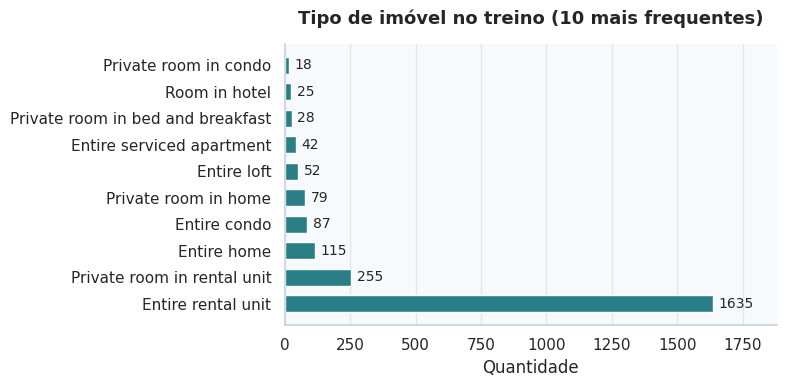

In [44]:
from pipeline_limpeza import Graficos

contagem = treino_imp['property_type'].value_counts()
print('categorias de property_type no treino:', len(contagem), '| com menos de 30 imóveis:', int((contagem < 30).sum()))
Graficos(treino_imp).barras_serie(contagem.head(10), 'Tipo de imóvel no treino (10 mais frequentes)', horizontal=True)


In [45]:
from pipeline_limpeza import TratadorTexto

treino_imp = TratadorTexto(treino_imp).agrupar_raras('property_type', minimo=30).dados
teste_imp = TratadorTexto(teste_imp).agrupar_raras('property_type', minimo=30, referencia=treino).dados
treino_imp['property_type'].value_counts().head(5)


INFO |   TratadorTexto | property_type: agrupei 32 categorias em 'Outros' (linhas removidas: 0)
INFO |   TratadorTexto | property_type: agrupei 32 categorias em 'Outros' (linhas removidas: 0)


property_type
Entire rental unit             1635
Private room in rental unit     255
Outros                          182
Entire home                     115
Entire condo                     87
Name: count, dtype: int64

In [48]:
treino_cod, teste_cod = TratadorTexto.dummies_treino_teste(
    treino_imp, teste_imp, ['room_type', 'property_type'])
print('colunas após one-hot:', treino_cod.shape[1])
print(treino_cod.filter(like='room_type').head(3))



colunas após one-hot: 33
   room_type_Entire home/apt  room_type_Private room  room_type_Shared room
0                          1                       0                      0
1                          1                       0                      0
2                          1                       0                      0


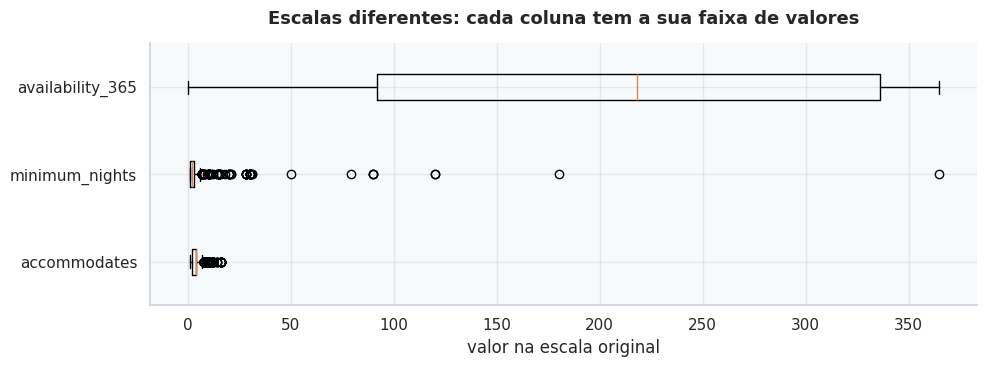

In [49]:
import matplotlib.pyplot as plt

numericas = ['accommodates', 'minimum_nights', 'availability_365']
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.boxplot([treino_cod[c].dropna() for c in numericas], orientation='horizontal', tick_labels=numericas)
ax.set_title('Escalas diferentes: cada coluna tem a sua faixa de valores')
ax.set_xlabel('valor na escala original')
plt.tight_layout()
plt.show()


In [54]:
from pipeline_limpeza import Escalonador

numericas = ['accommodates', 'minimum_nights', 'availability_365']
treino_mm, teste_mm = Escalonador.normalizar_minmax(treino_cod, teste_cod, numericas)
treino_z, teste_z = Escalonador.padronizar_treino_teste(treino_cod, teste_cod, numericas)
print('min-max no treino (mín, máx):', treino_mm.min().round(2).tolist(), treino_mm.max().round(2).tolist())
print('min-max no teste (mín, máx):', teste_mm.min().round(2).tolist(), teste_mm.max().round(2).tolist())
print('z-score no treino (média):', treino_z.mean().round(2).tolist())

print(treino_cod['availability_365'].head(4))
print(treino_mm['availability_365'].head(4))


min-max no treino (mín, máx): [0.0, 0.0, 0.0] [1.0, 1.0, 1.0]
min-max no teste (mín, máx): [0.0, 0.0, 0.0] [1.0, 0.16, 1.0]
z-score no treino (média): [0.0, -0.0, -0.0]
0    163
1    365
2    349
3    155
Name: availability_365, dtype: int64
0    0.446575
1    1.000000
2    0.956164
3    0.424658
Name: availability_365, dtype: float64


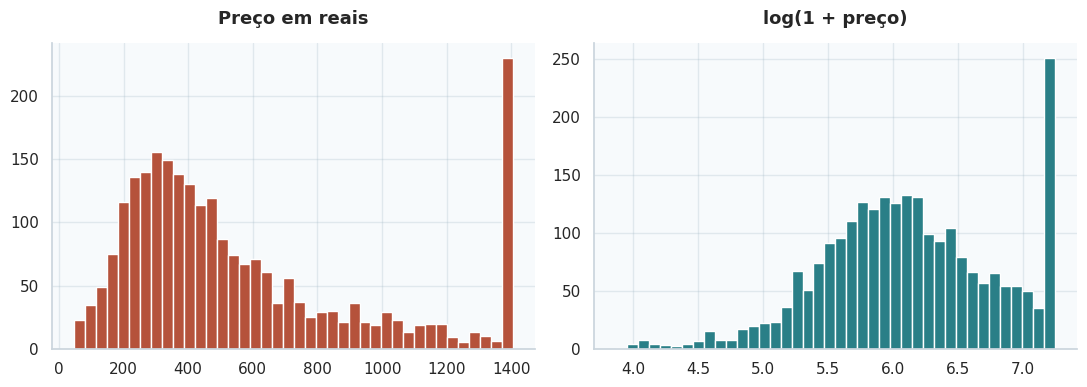

In [55]:
import numpy as np
import matplotlib.pyplot as plt

fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
eixos[0].hist(treino_cod['price'], bins=40, color='#B5523B', edgecolor='white')
eixos[0].set_title('Preço em reais')
eixos[1].hist(np.log1p(treino_cod['price']), bins=40, color='#2A7F87', edgecolor='white')
eixos[1].set_title('log(1 + preço)')
plt.tight_layout()
plt.show()


In [56]:
CONFIG = {
    'arquivo_bruto': 'dados/brutos/airbnb_rio_bruto.csv',
    'arquivo_limpo': 'dados/processados/airbnb_rio_limpo.csv',
    'fator_iqr': 1.5,
    'fracao_teste': 0.1,
    'semente': 42,
}
divisor = DivisorTreinoTeste(CONFIG['fracao_teste'], CONFIG['semente'])
print('Limiar do IQR:', CONFIG['fator_iqr'], '| semente:', CONFIG['semente'])


Limiar do IQR: 1.5 | semente: 42
